# Constrained Reverse KL Barycenters in 1D

This notebook covers the 1D part of the project that I worked on: adding a **probability constraint** to the reverse KL barycenter and checking the result numerically.

- **Sections 1–2** set up the example and the unconstrained barycenters. They come from our group's shared notebook and are included only so this notebook runs on its own.
- **Sections 3–6** are my work: the constrained barycenter, the forward vs reverse KL comparison, a numerical check of the closed form, and the two-Gaussian constraint experiments.

## 1. Setup: KDEs from a bimodal distribution *(group notebook)*

We draw $M=10$ small samples ($N=5$ points each) from the mixture $\tfrac12 N(-2,0.5^2)+\tfrac12 N(2,0.5^2)$ and fit a Gaussian KDE to each one. Every KDE is evaluated on a grid and turned into a strictly positive probability vector, so all KL divergences are finite.

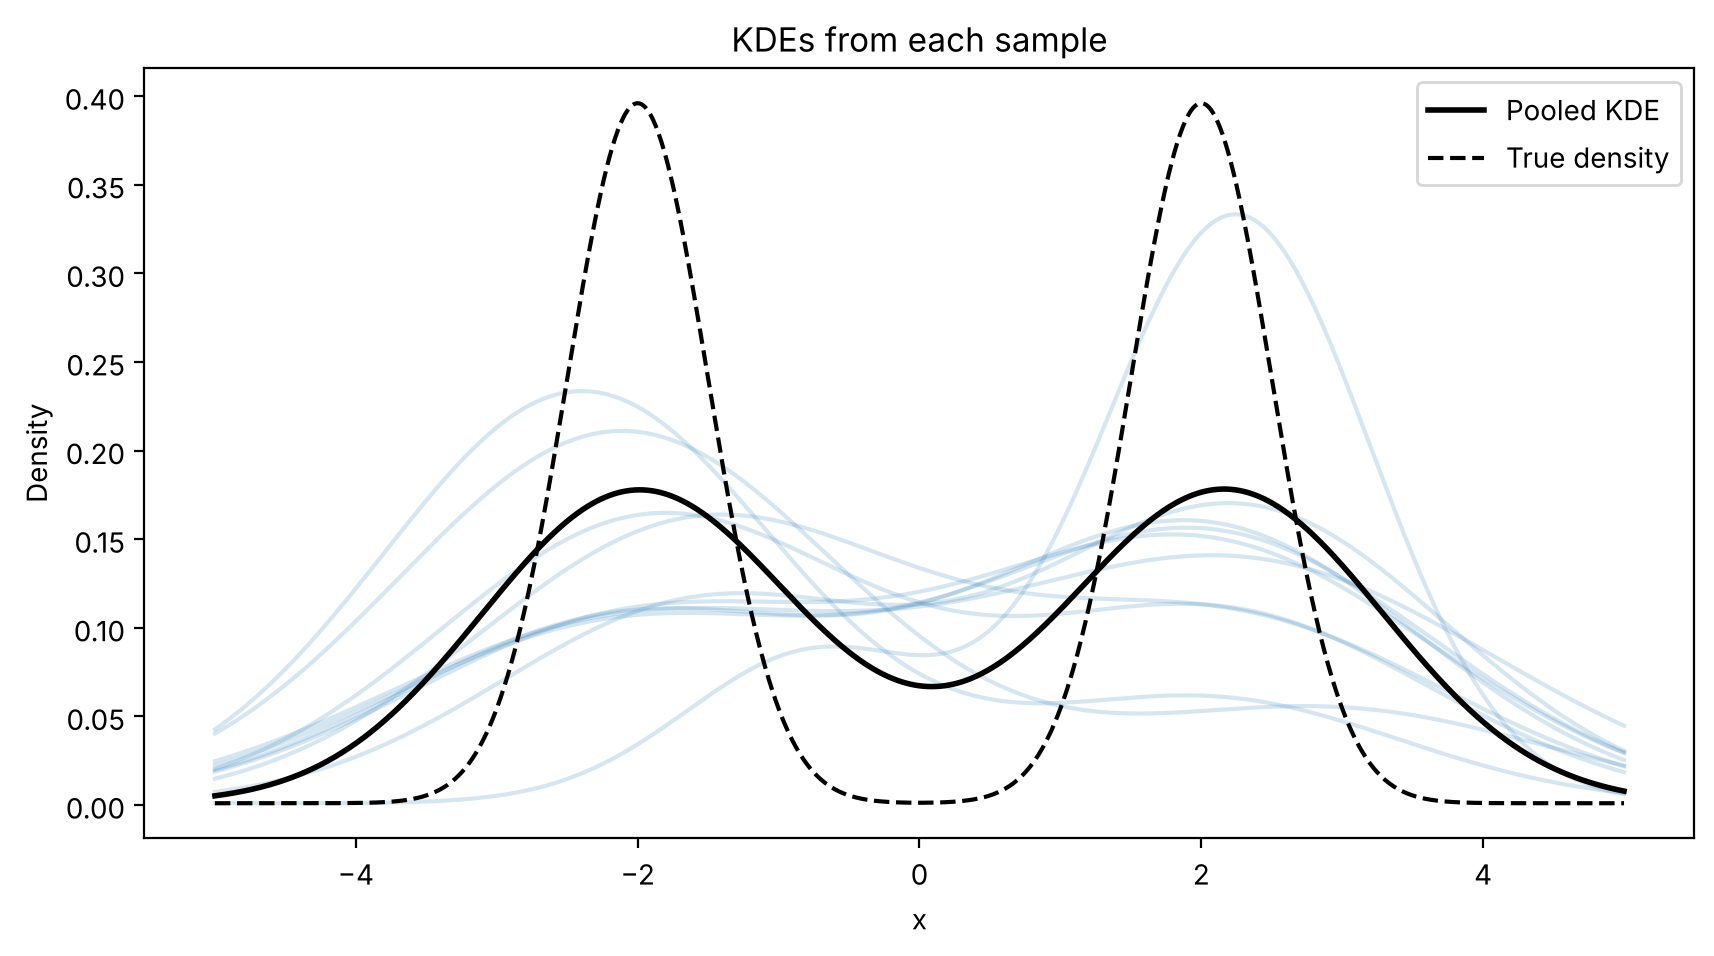

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

FIG = "../figures"
os.makedirs(FIG, exist_ok=True)
np.random.seed(0)

phi = lambda z: np.exp(-z**2 / 2) / np.sqrt(2 * np.pi)   # Gaussian kernel

def gaussian_kde(x, data, h):
    z = (x.reshape(-1, 1) - data.reshape(1, -1)) / h
    return np.sum(phi(z), axis=1) / (len(data) * h)

def normalize(f):
    # normalise, add a small floor so no grid point has zero mass, normalise again
    f = f / np.sum(f)
    f += 1 / (100 * len(f))
    return f / np.sum(f)

def sample_bimodal(N):
    H = np.random.rand(N) < 0.5
    return H * np.random.normal(-2, 0.5, N) + (1 - H) * np.random.normal(2, 0.5, N)

M, N = 10, 5
data = [sample_bimodal(N) for _ in range(M)]

x = np.linspace(-5, 5, 1001)
dx = x[1] - x[0]

kdes = np.array([normalize(gaussian_kde(x, d, 1.06 * np.std(d) * len(d) ** (-1 / 5))) for d in data])

all_data = np.concatenate(data)
total_kde = normalize(gaussian_kde(x, all_data, 1.06 * np.std(all_data) * len(all_data) ** (-1 / 5)))
true_density = normalize(0.5 * phi((x + 2) / 0.5) / 0.5 + 0.5 * phi((x - 2) / 0.5) / 0.5)

plt.figure(figsize=(10, 5))
for j in range(M):
    plt.plot(x, kdes[j] / dx, color="tab:blue", alpha=0.18)
plt.plot(x, total_kde / dx, color="black", linewidth=2, label="Pooled KDE")
plt.plot(x, true_density / dx, color="black", linestyle="--", label="True density")
plt.xlabel("x"); plt.ylabel("Density"); plt.title("KDEs from each sample"); plt.legend()
plt.show()

## 2. Unconstrained barycenters *(group notebook)*

For distributions $p_1,\dots,p_m$ on a common grid with weights $\pi_j$:

| Barycenter | Objective | Solution |
|---|---|---|
| Reverse KL | $\min_q \sum_j \pi_j\,\mathrm{KL}(q\,\|\,p_j)$ | normalised **geometric** mean $\prod_j p_j^{\pi_j}$ |
| Forward KL | $\min_q \sum_j \pi_j\,\mathrm{KL}(p_j\,\|\,q)$ | **arithmetic** mean $\sum_j \pi_j p_j$ |
| Reverse $\chi^2$ | $\min_q \sum_j \pi_j\,\chi^2(q\,\|\,p_j)$ | normalised **harmonic** mean $\big(\sum_j \pi_j p_j^{-1}\big)^{-1}$ |

In [2]:
def reverse_barycenter(f, pi=None):
    pi = np.full(len(f), 1 / len(f)) if pi is None else np.asarray(pi)
    return normalize(np.prod(f ** pi[:, None], axis=0))

def forward_barycenter(f, pi=None):
    pi = np.full(len(f), 1 / len(f)) if pi is None else np.asarray(pi)
    return normalize(np.sum(f * pi[:, None], axis=0))

def reverse_chi2_barycenter(f, pi=None):
    pi = np.full(len(f), 1 / len(f)) if pi is None else np.asarray(pi)
    return normalize(1 / np.sum(pi[:, None] / f, axis=0))

def KL(p, q):
    return np.sum(p * np.log(p / q))

## 3. Constrained reverse KL barycenter *(my work)*

We add prior information about the aggregate model, here $P_q(X<0)=0.75$. Following the poster, write the constraint as $\mathbb{E}_q[h(X)]=0$ with the two-valued function

$$
h(x)=\begin{cases} a = 0.25, & x<0\\ b=-0.75, & x\ge 0\end{cases}
\qquad\Longrightarrow\qquad
\mathbb{E}_q[h] = 0.25\,P_q(X<0) - 0.75\,P_q(X\ge 0) = 0 \iff P_q(X<0)=0.75 .
$$

The solution is an exponential tilt of the unconstrained (geometric-mean) barycenter $q^b$:

$$
q^*(x)\propto e^{-\mu^* h(x)}\,q^b(x).
$$

Let $P_A=\sum_{x<0} q^b(x)$ and $P_B=\sum_{x\ge0} q^b(x)$. The condition $\mathbb{E}_{q^*}[h]=0$ becomes $a P_A e^{-\mu a} + b P_B e^{-\mu b}=0$, so

$$
\mu^*=\frac{1}{a-b}\,\log\frac{a\,P_A}{-b\,P_B}.
$$

In [3]:
def constrained_h_barycenter(f, x, a=0.25, b=-0.75, pi=None):
    # two-valued h: a on {x < 0}, b on {x >= 0}
    h = np.where(x < 0, a, b)

    pi = np.full(len(f), 1 / len(f)) if pi is None else np.asarray(pi)
    g = np.prod(f ** pi[:, None], axis=0)      # unnormalised geometric mean, prod_j p_j(i)^pi_j

    P_A = np.sum(g[x < 0])
    P_B = np.sum(g[x >= 0])
    mu = np.log((a * P_A) / (-b * P_B)) / (a - b)

    g_star = np.exp(-mu * h) * g
    return g_star / np.sum(g_star), mu

rev = reverse_barycenter(kdes)
fwd = forward_barycenter(kdes)
chi2 = reverse_chi2_barycenter(kdes)
con, mu_closed = constrained_h_barycenter(kdes, x)

print(f"mu* (closed form)             = {mu_closed:.6f}")
print(f"P(X<0), unconstrained reverse = {rev[x < 0].sum():.4f}")
print(f"P(X<0), constrained           = {con[x < 0].sum():.4f}   (target 0.75)")

mu* (closed form)             = -1.199136
P(X<0), unconstrained reverse = 0.4751
P(X<0), constrained           = 0.7500   (target 0.75)


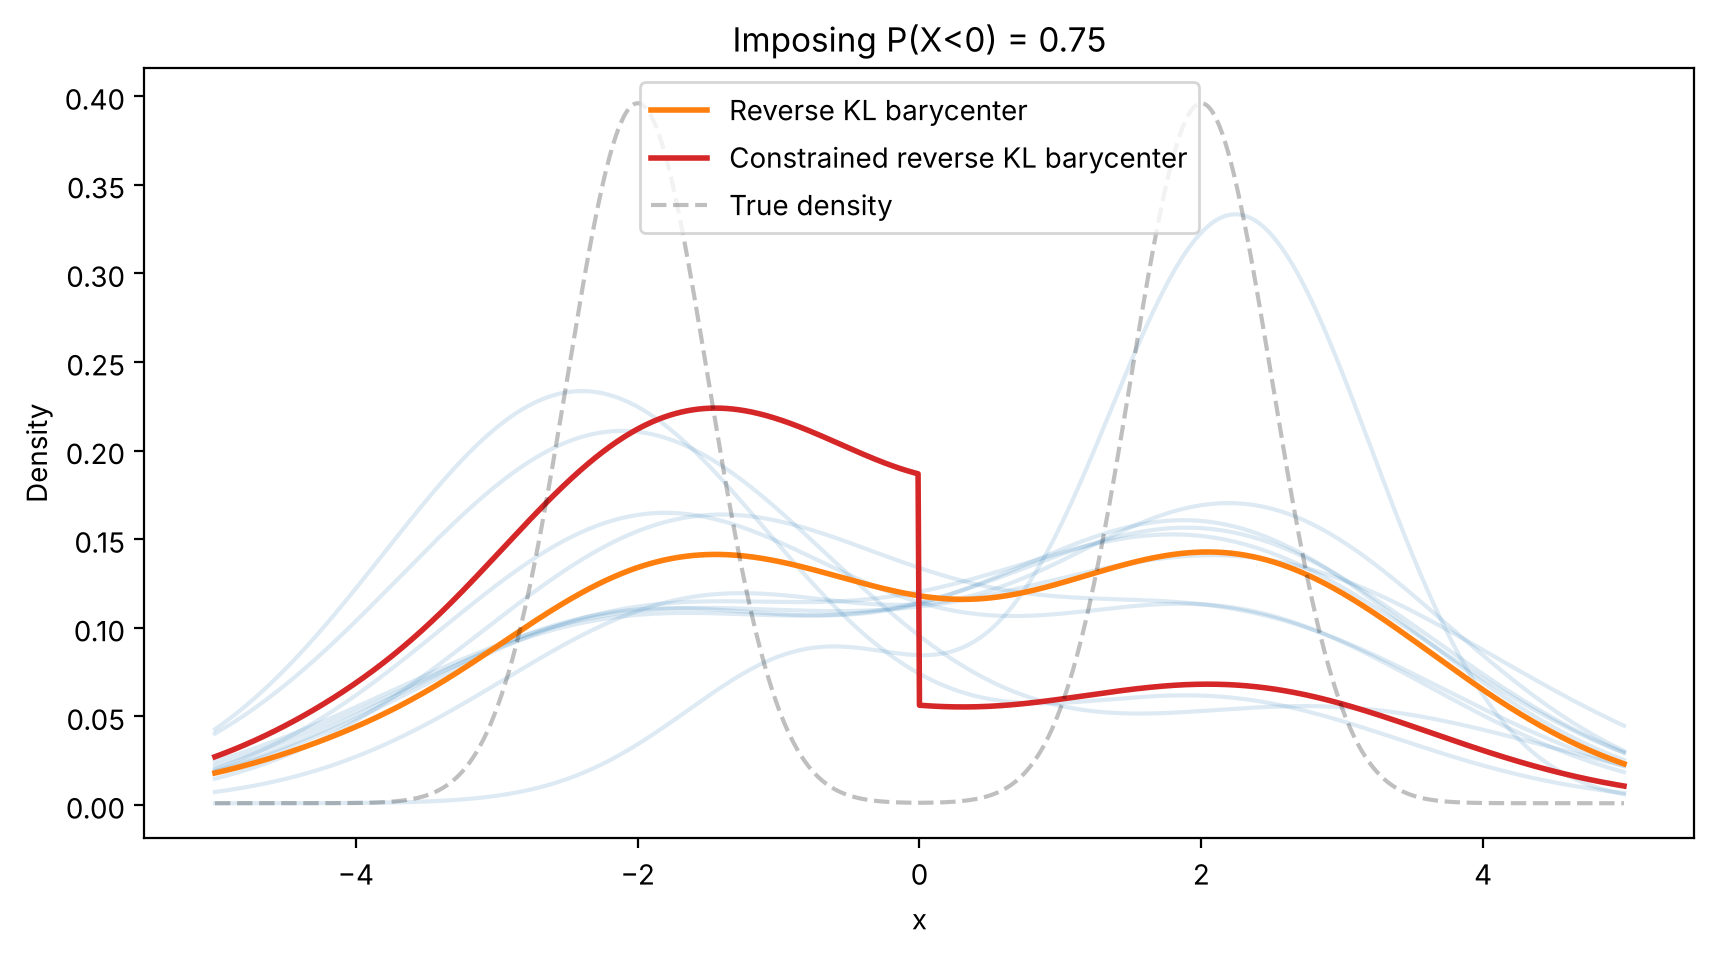

In [4]:
plt.figure(figsize=(10, 5))
for j in range(M):
    plt.plot(x, kdes[j] / dx, color="tab:blue", alpha=0.15)
plt.plot(x, rev / dx, color="tab:orange", linewidth=2, label="Reverse KL barycenter")
plt.plot(x, con / dx, color="tab:red", linewidth=2, label="Constrained reverse KL barycenter")
plt.plot(x, true_density / dx, color="black", alpha=0.25, linestyle="--", label="True density")
plt.xlabel("x"); plt.ylabel("Density"); plt.title("Imposing P(X<0) = 0.75"); plt.legend()
plt.savefig(f"{FIG}/1d_constrained_barycenter.png", dpi=150, bbox_inches="tight")
plt.show()

The constrained barycenter keeps the shape of the reverse KL barycenter on each side of $0$; it only rescales the two sides. The jump at $x=0$ is expected, because $h$ is a step function.

## 4. Forward vs reverse KL: which barycenter wins which objective? *(my work)*

KL is not symmetric, so the two barycenters minimise different objectives. The reverse barycenter should have the smallest $\sum_j \mathrm{KL}(q\,\|\,\mathrm{KDE}_j)$ and the forward barycenter the smallest $\sum_j \mathrm{KL}(\mathrm{KDE}_j\,\|\,q)$.

In [5]:
candidates = {
    "reverse KL": rev,
    "forward KL": fwd,
    "constrained reverse KL": con,
    "reverse chi-squared": chi2,
}

print(f"{'barycenter q':<26}{'sum_j KL(q || KDE_j)':>24}{'sum_j KL(KDE_j || q)':>24}")
for name, q in candidates.items():
    rev_obj = sum(KL(q, k) for k in kdes)
    fwd_obj = sum(KL(k, q) for k in kdes)
    print(f"{name:<26}{rev_obj:>24.4f}{fwd_obj:>24.4f}")

barycenter q                  sum_j KL(q || KDE_j)    sum_j KL(KDE_j || q)
reverse KL                                  1.0787                  0.8661
forward KL                                  1.1284                  0.8219
constrained reverse KL                      2.6506                  2.4275
reverse chi-squared                         1.3955                  1.6008


As expected, the reverse KL barycenter has the smallest value in the first column and the forward KL barycenter in the second. The constrained barycenter pays a price in both, because it is optimal only *within* the constraint set.

## 5. Numerical check of the closed form *(my work)*

For a general $h$ there is no closed-form $\mu^*$, so we solve $\mathbb{E}_{q_\mu}[h]=0$ by root finding (Brent's method) and compare with Section 3.

In [6]:
from scipy.optimize import root_scalar

def constrained_barycenter_root(f, h, pi=None, bracket=(-100, 100)):
    pi = np.full(len(f), 1 / len(f)) if pi is None else np.asarray(pi)
    log_g = np.sum(pi[:, None] * np.log(f), axis=0)

    def q_mu(mu):
        w = np.exp(log_g - mu * h - np.max(log_g - mu * h))
        return w / w.sum()

    sol = root_scalar(lambda mu: np.sum(q_mu(mu) * h), bracket=bracket, method="brentq")
    if not sol.converged:
        raise RuntimeError("Root finding failed.")
    return q_mu(sol.root), sol.root

h = np.where(x < 0, 0.25, -0.75)
q_root, mu_root = constrained_barycenter_root(kdes, h)

print(f"mu* closed form = {mu_closed:.8f}")
print(f"mu* root find   = {mu_root:.8f}")
print(f"E_q[h]          = {np.sum(q_root * h):.2e}")
print(f"max |q_root - q_closed| = {np.max(np.abs(q_root - con)):.2e}")

mu* closed form = -1.19913619
mu* root find   = -1.19913619
E_q[h]          = -5.55e-17
max |q_root - q_closed| = 3.90e-18


## 6. Two Gaussians: how the constraint moves the barycenter *(my work)*

Take $p_0=N(-2,0.8^2)$, $p_1=N(3,2^2)$ with equal weights. The unconstrained reverse KL barycenter is the normalised geometric mixture $p_0^{1/2}p_1^{1/2}$, which is again Gaussian. We impose $P_q(X\le x_0)=c$:

- **Case 1:** fix $x_0=0$, vary $c$.
- **Case 2:** fix $c=0.5$, vary $x_0$.

With $A=\int_{-\infty}^{x_0} q^b$ and $B=\int_{x_0}^{\infty} q^b$, the constrained solution multiplies the left part by $e^{-\eta}$ with $\eta=\log\frac{(1-c)A}{cB}$, which gives left mass exactly $c$.

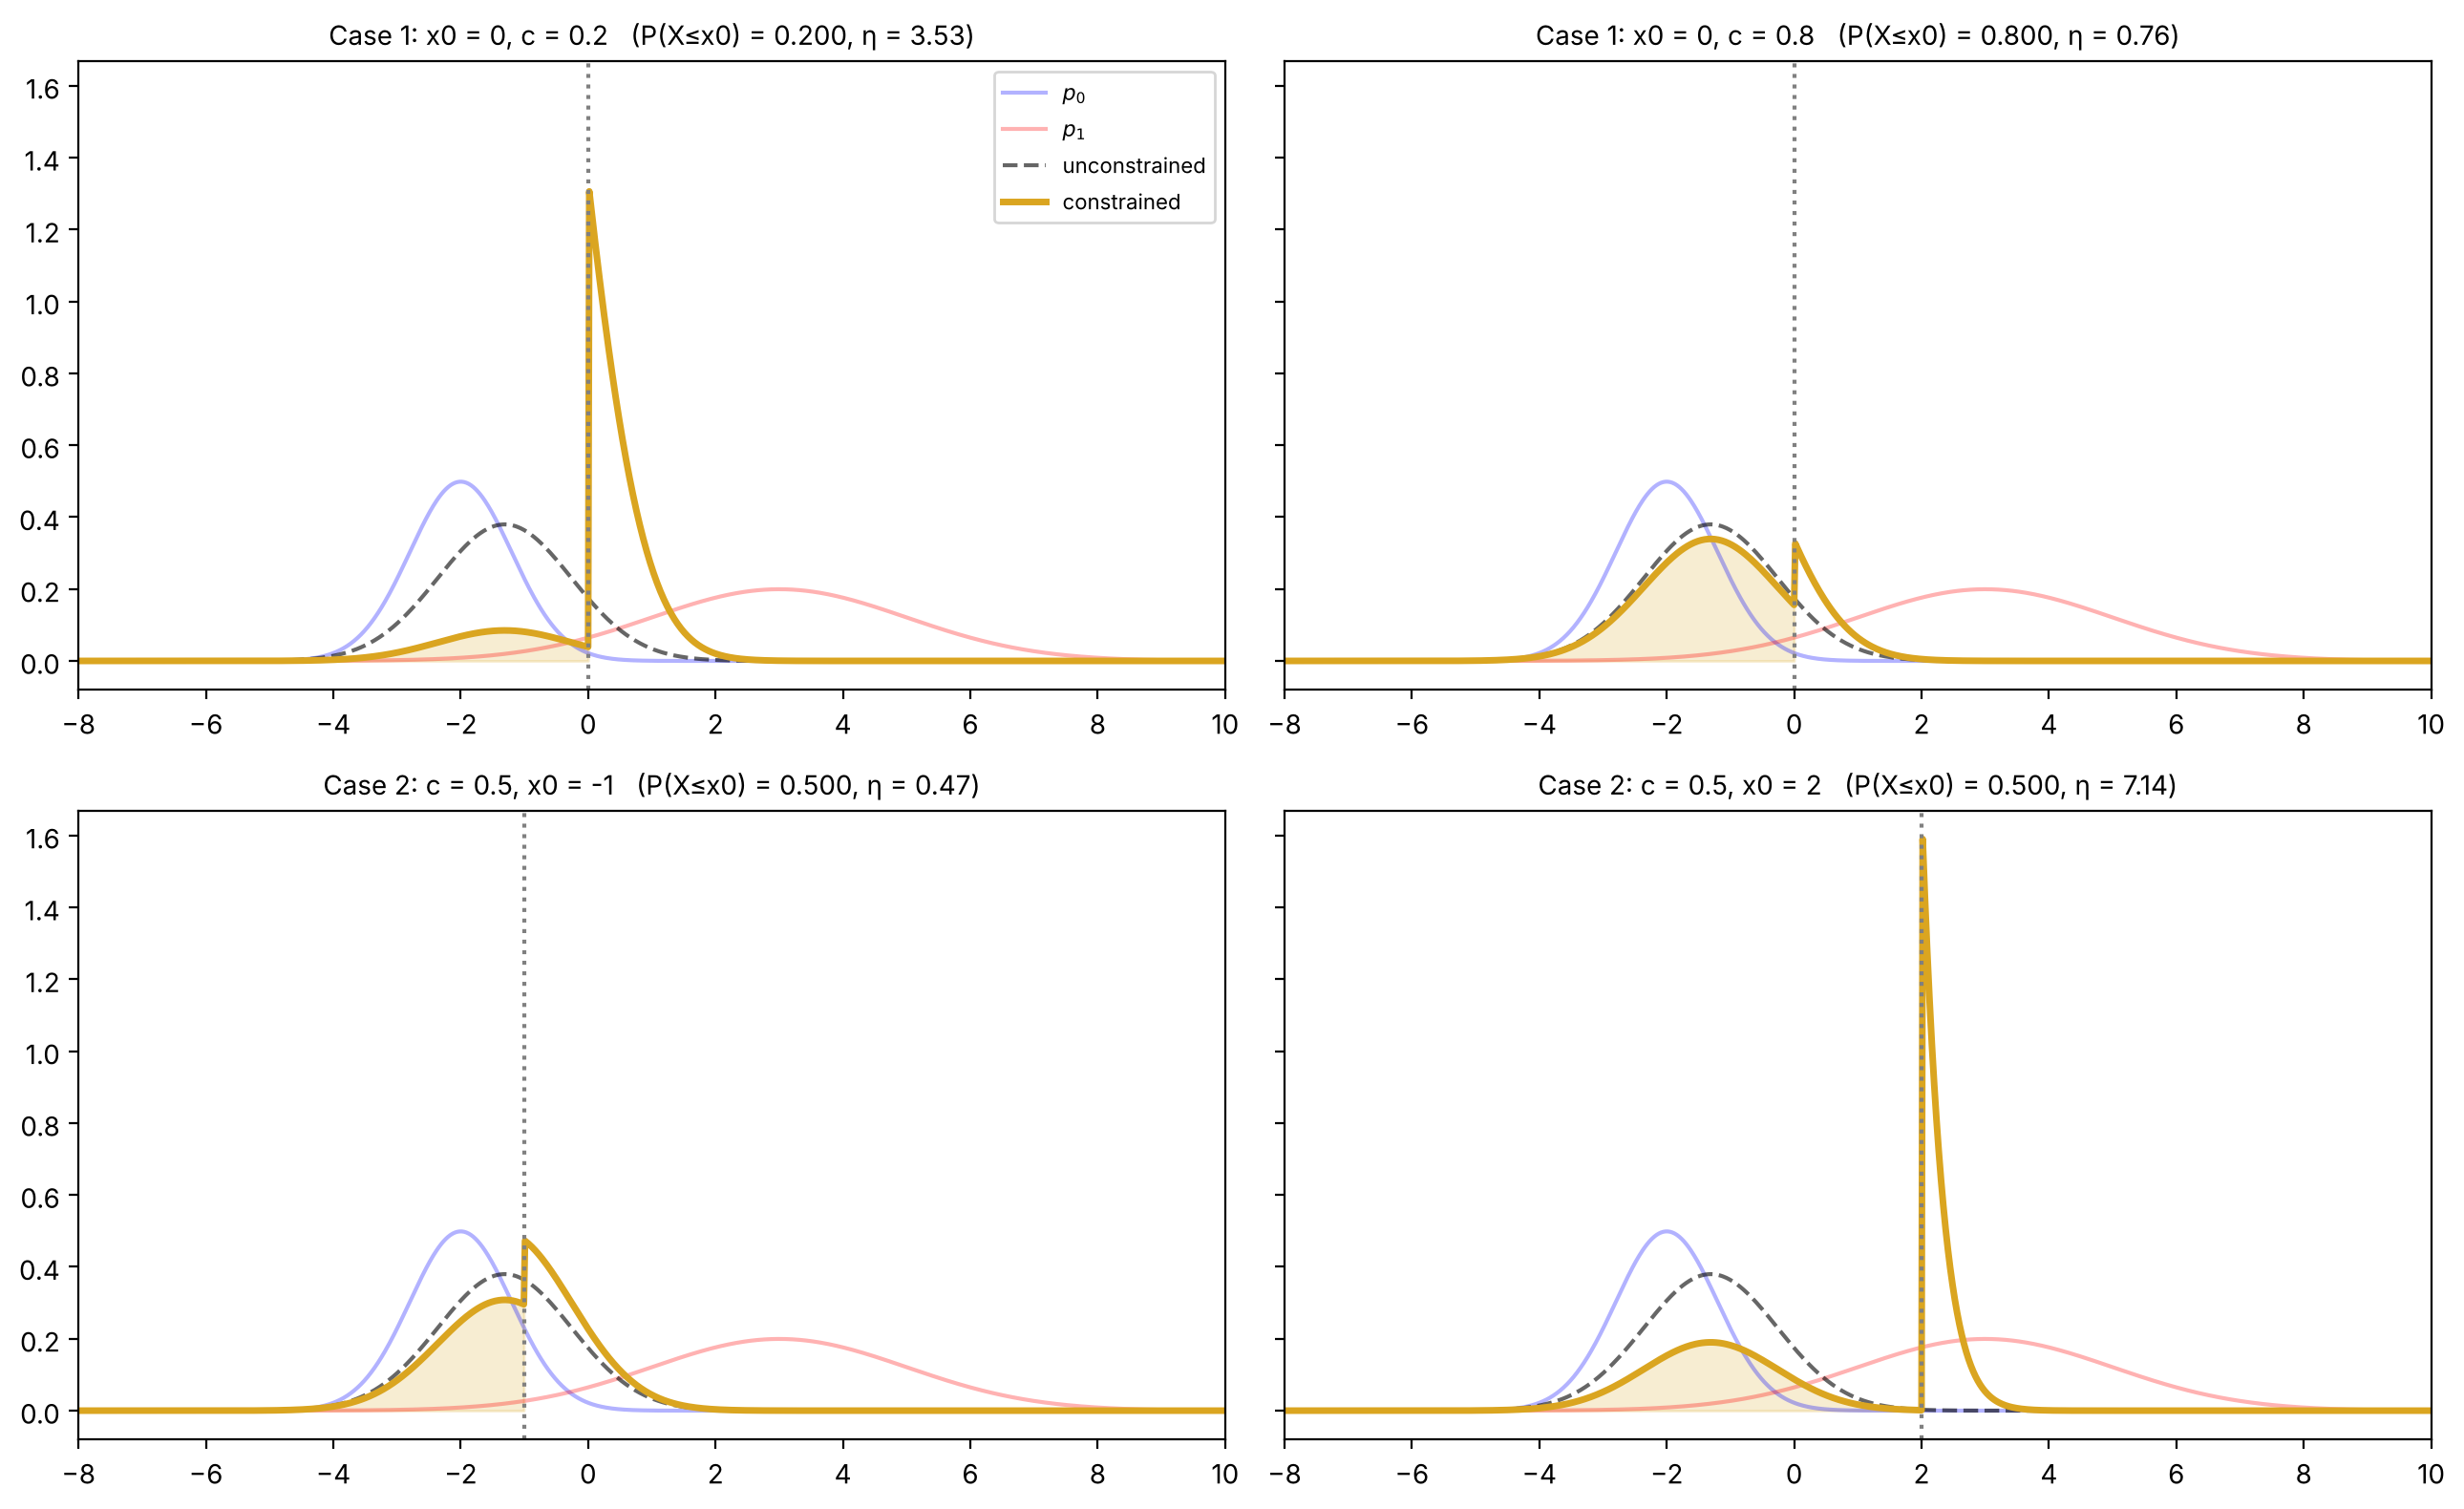

In [7]:
mu0, s0, mu1, s1 = -2, 0.8, 3, 2.0
xg = np.linspace(-8, 10, 1000)
dxg = xg[1] - xg[0]
gauss = lambda t, m, s: np.exp(-(t - m) ** 2 / (2 * s ** 2)) / (np.sqrt(2 * np.pi) * s)
p0, p1 = gauss(xg, mu0, s0), gauss(xg, mu1, s1)

lam = 0.5
log_geo = (1 - lam) * np.log(p0) + lam * np.log(p1)
geo = np.exp(log_geo - log_geo.max())
q_unc = geo / (geo.sum() * dxg)

def constrain(x0, c):
    left = xg <= x0
    A, B = geo[left].sum() * dxg, geo[~left].sum() * dxg
    eta = np.log((1 - c) * A / (c * B))
    q = geo.copy()
    q[left] *= np.exp(-eta)
    return q / (q.sum() * dxg), eta

cases = [("Case 1: x0 = 0, c = 0.2", 0.0, 0.2), ("Case 1: x0 = 0, c = 0.8", 0.0, 0.8),
         ("Case 2: c = 0.5, x0 = -1", -1.0, 0.5), ("Case 2: c = 0.5, x0 = 2", 2.0, 0.5)]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for ax, (title, x0, c) in zip(axes.ravel(), cases):
    q, eta = constrain(x0, c)
    mass = q[xg <= x0].sum() * dxg
    ax.plot(xg, p0, "b-", alpha=0.3, label="$p_0$")
    ax.plot(xg, p1, "r-", alpha=0.3, label="$p_1$")
    ax.plot(xg, q_unc, "k--", alpha=0.6, label="unconstrained")
    ax.plot(xg, q, color="goldenrod", linewidth=2.5, label="constrained")
    ax.axvline(x0, color="gray", linestyle=":")
    ax.fill_between(xg[xg <= x0], q[xg <= x0], alpha=0.2, color="goldenrod")
    ax.set_title(f"{title}   (P(X≤x0) = {mass:.3f}, η = {eta:.2f})", fontsize=10)
    ax.set_xlim(-8, 10)
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIG}/1d_two_gaussians_constraint.png", dpi=150, bbox_inches="tight")
plt.show()

In every panel the constrained barycenter hits the target mass exactly. Inside each region it keeps the shape of the unconstrained barycenter, and the farther $c$ is from the unconstrained value $P_{q^b}(X\le x_0)$, the larger the jump at $x_0$.